# CatBoost + Logistic Regression — Kaggle Classification

End-to-end, runnable notebook for your dataset (`train_data.csv`, `test_data.csv`, `sample_solution.csv`). Compares **regularized Logistic Regression**, **CatBoost**, and a **probability blend**, scores with **ROC-AUC**, then refits on all labeled data to write Kaggle submissions. Designed to run on an Apple M2 without a costly 200-fit search.

**Important:** A Kaggle ROC-AUC of 0.75 is a goal, not a guaranteed result. Keep the validation split fixed and do not tune to repeated leaderboard submissions.

In [ ]:
# Uncomment once if packages are missing:
# %pip install -q pandas numpy scikit-learn catboost matplotlib

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from catboost import CatBoostClassifier

RANDOM_STATE = 42
DATA_DIR = Path('/Users/nilavaghosh/Desktop/E82Advanced ML/Homeworks/HW3/ml_classifier_experiments/src/')
TRAIN_PATH = DATA_DIR / 'train_data.csv'
TEST_PATH = DATA_DIR / 'test_data.csv'
SAMPLE_PATH = DATA_DIR / 'sample_solution.csv'
for p in (TRAIN_PATH, TEST_PATH, SAMPLE_PATH):
    if not p.exists():
        raise FileNotFoundError(f'Missing: {p.resolve()} — update DATA_DIR to your dataset folder')

## 1. Load data and inspect columns

Use the training features as the source of truth. Do **not** include `output` or an ID field in model features.

In [4]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
sample_solution = pd.read_csv(SAMPLE_PATH)
assert 'output' in train.columns, 'Training data must have an output column'
assert 'output' in sample_solution.columns, 'Sample solution must have an output column'
assert len(test) == len(sample_solution), 'Test rows must align with sample solution rows'

id_cols = [c for c in ['id'] if c in train.columns]
feature_cols = [c for c in train.columns if c not in ['output', *id_cols]]
missing_test_cols = set(feature_cols) - set(test.columns)
if missing_test_cols:
    raise ValueError(f'Test data is missing feature columns: {sorted(missing_test_cols)[:15]}')
X = train[feature_cols].copy()
y = train['output'].copy()
X_test = test[feature_cols].copy()
assert y.dropna().isin([0, 1]).all() and not y.isna().any(), 'Output must be binary 0/1 and not missing'
print('Training:', X.shape, 'Test:', X_test.shape)
##print('Class distribution:', y.value_counts(dropna=False))
print('Missing values (train):', int(X.isna().sum().sum()))
print('Sample solution columns:', list(sample_solution.columns))

Training: (4584, 669) Test: (1732, 669)
Missing values (train): 0
Sample solution columns: ['id', 'output']


## 2. Identify categorical vs numeric features

Treat `subject`, `phase`, and `state` as categorical if present (including numerically encoded `phase`). Other object/string/category columns are also treated as categorical.

In [5]:
known_cats = {'subject', 'phase', 'state'}
cat_cols = [c for c in feature_cols if c in known_cats or not pd.api.types.is_numeric_dtype(X[c])]
num_cols = [c for c in feature_cols if c not in cat_cols]
print('Categorical features:', cat_cols)
print('Numerical feature count:', len(num_cols))

# Ensure identical handling on training/validation/test data.
def prepare_catboost(df):
    out = df[feature_cols].copy()
    for col in cat_cols:
        out[col] = out[col].astype('string').fillna('__MISSING__').astype(str)
    for col in num_cols:
        out[col] = pd.to_numeric(out[col], errors='coerce').astype(float)
        # CatBoost supports numeric NaN, not infinite values.
        out[col] = out[col].replace([np.inf, -np.inf], np.nan)
    return out

# Clean numeric infinity values for sklearn, too.
X[num_cols] = X[num_cols].replace([np.inf, -np.inf], np.nan)
X_test[num_cols] = X_test[num_cols].replace([np.inf, -np.inf], np.nan)

Categorical features: ['subject', 'phase', 'state']
Numerical feature count: 666


## 3. One stratified holdout split

All preprocessing is learned **only on the training fold**, preventing validation leakage.

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print('Train:', X_train.shape, 'Validation:', X_val.shape)

# Handles numeric median imputation + scaling and categorical imputation + one-hot encoding.
# sklearn compatibility: sparse_output (newer) vs sparse (older).
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=True)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=True)

transformers = []
if num_cols:
    transformers.append(('numeric', Pipeline([
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
        ('scaler', StandardScaler(with_mean=False))
    ]), num_cols))
if cat_cols:
    transformers.append(('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', ohe)
    ]), cat_cols))
preprocessor = ColumnTransformer(transformers, remainder='drop', sparse_threshold=1.0)

Train: (3667, 669) Validation: (917, 669)


## 4. Logistic Regression (L2 regularization)

Try keeping all features instead of potentially discarding useful signals through L1 selection. `liblinear` is generally efficient at this dataset size.

In [7]:
lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        penalty='l2', solver='liblinear', C=0.1,
        class_weight=None, max_iter=2000, random_state=RANDOM_STATE
    ))
])
lr_model.fit(X_train, y_train)
lr_val_probs = lr_model.predict_proba(X_val)[:, 1]
lr_auc = roc_auc_score(y_val, lr_val_probs)
print(f'Logistic Regression validation ROC-AUC: {lr_auc:.5f}')

/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Logistic Regression validation ROC-AUC: 0.79440


## 5. CatBoost (early stopping)

CatBoost uses raw categorical columns and numeric missing values directly. A modest number of trees and early stopping keeps the notebook reasonably fast.

In [8]:
X_train_cb = prepare_catboost(X_train)
X_val_cb = prepare_catboost(X_val)

cb_model = CatBoostClassifier(
    iterations=900, depth=5, learning_rate=0.035,
    l2_leaf_reg=5, loss_function='Logloss', eval_metric='AUC',
    random_seed=RANDOM_STATE, thread_count=4,
    verbose=False, allow_writing_files=False
)
cb_model.fit(
    X_train_cb, y_train,
    cat_features=cat_cols,
    eval_set=(X_val_cb, y_val),
    early_stopping_rounds=80,
    verbose=False
)
cb_val_probs = cb_model.predict_proba(X_val_cb)[:, 1]
cb_auc = roc_auc_score(y_val, cb_val_probs)
print(f'CatBoost validation ROC-AUC: {cb_auc:.5f}')
print('Best CatBoost iteration:', cb_model.best_iteration_)

CatBoost validation ROC-AUC: 0.88525
Best CatBoost iteration: 450


## 6. Blend predictions and compare ROC-AUC

The blend mixes *predicted probabilities*, never hard `0/1` labels. Weight selection on a single validation holdout can overfit, so treat the grid as exploratory. For a more rigorous estimate, use out-of-fold predictions.

In [10]:
blend_rows = []
for cat_weight in np.arange(0, 1.01, 0.1):
    probs = cat_weight * cb_val_probs + (1 - cat_weight) * lr_val_probs
    blend_rows.append({'catboost_weight': round(float(cat_weight), 1),
                       'logistic_weight': round(float(1-cat_weight), 1),
                       'validation_auc': roc_auc_score(y_val, probs)})
blend_results = pd.DataFrame(blend_rows).sort_values('validation_auc', ascending=False)
print(blend_results.to_string(index=False))
best_weight = float(blend_results.iloc[0]['catboost_weight'])
blend_val_probs = best_weight*cb_val_probs + (1-best_weight)*lr_val_probs
summary = pd.DataFrame({
    'model': ['Logistic Regression', 'CatBoost', f'Blend (CatBoost weight={best_weight:.1f})'],
    'validation_roc_auc': [lr_auc, cb_auc, roc_auc_score(y_val, blend_val_probs)]
}).sort_values('validation_roc_auc', ascending=False)
print('Model comparison:', summary.to_string(index=False))

 catboost_weight  logistic_weight  validation_auc
             1.0              0.0        0.885252
             0.9              0.1        0.881863
             0.8              0.2        0.878037
             0.7              0.3        0.872422
             0.6              0.4        0.866524
             0.5              0.5        0.858819
             0.4              0.6        0.849696
             0.3              0.7        0.839173
             0.2              0.8        0.826397
             0.1              0.9        0.811422
             0.0              1.0        0.794403
Model comparison:                       model  validation_roc_auc
                   CatBoost            0.885252
Blend (CatBoost weight=1.0)            0.885252
        Logistic Regression            0.794403


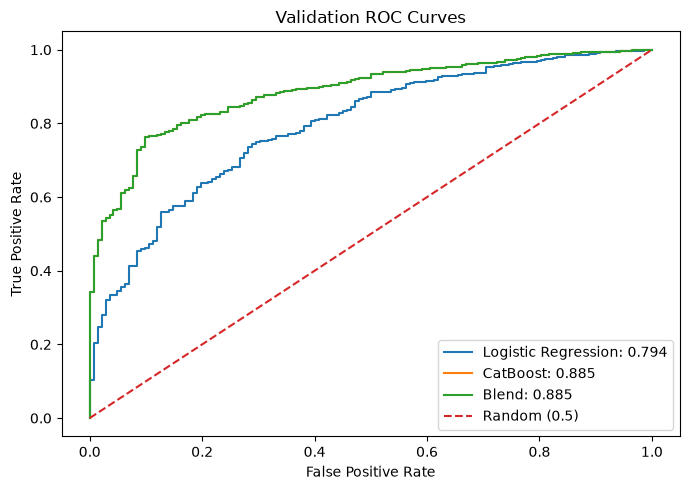

In [11]:
plt.figure(figsize=(7,5))
for label, probs in [('Logistic Regression', lr_val_probs),
                     ('CatBoost', cb_val_probs), ('Blend', blend_val_probs)]:
    fpr, tpr, _ = roc_curve(y_val, probs)
    plt.plot(fpr, tpr, label=f'{label}: {roc_auc_score(y_val, probs):.3f}')
plt.plot([0,1],[0,1],'--',label='Random (0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Validation ROC Curves')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Explainability: CatBoost feature importance and LR coefficients

CatBoost built-in importance measures a feature's contribution to model predictions; for LR, coefficient magnitudes are on the *transformed* feature scale. These explanations are not causal.

CatBoost top 20 features: subject    21.730814
phase       4.379522
x217        1.355881
y7          0.945016
x203        0.840916
y107        0.818091
x60         0.730262
y213        0.685405
y70         0.669350
y197        0.655227
z75         0.617546
z218        0.614885
z203        0.612703
y208        0.592567
z68         0.586114
x207        0.555994
x112        0.546350
z79         0.503445
y202        0.499248
y82         0.468006
dtype: float64


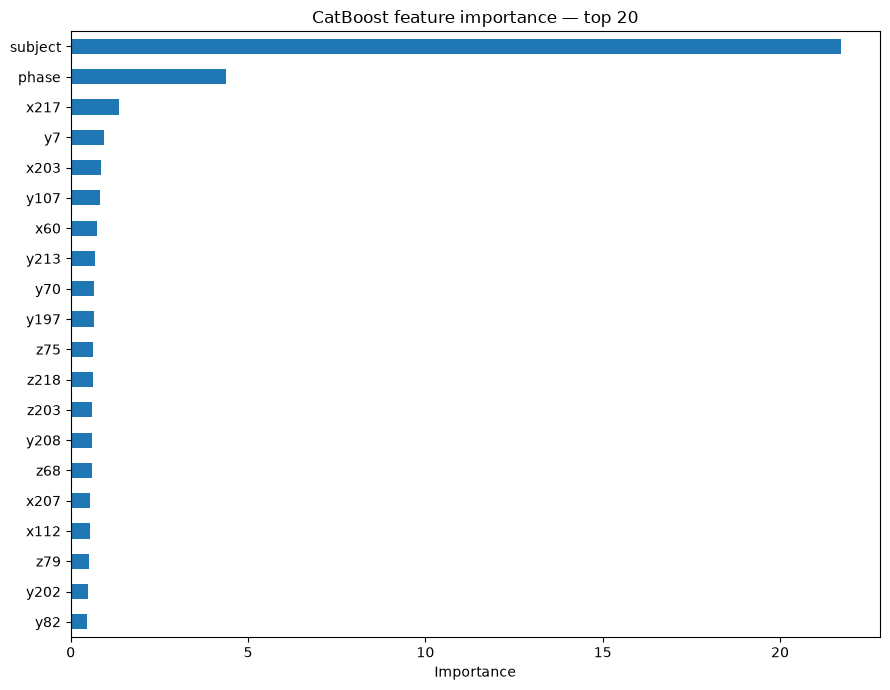

Logistic Regression top 20 absolute coefficients: categorical__subject_G   -1.567062
categorical__subject_K    1.441841
categorical__subject_A    0.770502
categorical__subject_M   -0.764793
categorical__subject_C   -0.702805
categorical__subject_F   -0.576097
categorical__subject_L    0.559676
categorical__subject_I    0.553771
categorical__subject_D    0.391395
numeric__y15             -0.377607
numeric__y139            -0.357271
categorical__phase_2     -0.356409
numeric__x8              -0.326856
numeric__y69              0.324773
numeric__z66              0.315187
numeric__y62              0.302891
numeric__y58              0.302814
numeric__x108             0.298056
numeric__y107            -0.287936
numeric__x221            -0.285044
dtype: float64


In [13]:
cb_importance = pd.Series(cb_model.get_feature_importance(), index=feature_cols).sort_values(ascending=False)
print('CatBoost top 20 features:', cb_importance.head(20))
ax = cb_importance.head(20).sort_values().plot.barh(figsize=(9,7), title='CatBoost feature importance — top 20')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

try:
    names = lr_model.named_steps['preprocessor'].get_feature_names_out()
    lr_coeff = pd.Series(lr_model.named_steps['classifier'].coef_[0], index=names)
    print('Logistic Regression top 20 absolute coefficients:',
          lr_coeff.reindex(lr_coeff.abs().sort_values(ascending=False).head(20).index))
except (AttributeError, ValueError) as exc:
    print('Could not display coefficient names:', exc)

## 8. Refit on ALL labeled training rows, then generate Kaggle submissions

Refitting uses all 4,584 labeled rows (if that is your current dataset). For CatBoost, use the holdout's `best_iteration + 1` as an approximate tree count, with **no validation early stopping** during the final refit. Saves standalone and blended files. The output format matches `sample_solution.csv` exactly.

In [15]:
# Fresh models for full-data refit. Preserve fitted models above for validation analysis.
from sklearn.base import clone
lr_final = clone(lr_model)
lr_final.fit(X, y)

best_trees = max(50, (cb_model.best_iteration_ or 0) + 1)
cb_final = CatBoostClassifier(
    iterations=best_trees, depth=5, learning_rate=0.035,
    l2_leaf_reg=5, loss_function='Logloss', eval_metric='AUC',
    random_seed=RANDOM_STATE, thread_count=4,
    verbose=False, allow_writing_files=False
)
cb_final.fit(prepare_catboost(X), y, cat_features=cat_cols, verbose=False)

lr_test_probs = lr_final.predict_proba(X_test)[:,1]
cb_test_probs = cb_final.predict_proba(prepare_catboost(X_test))[:,1]
blend_test_probs = best_weight*cb_test_probs + (1-best_weight)*lr_test_probs

files = {
    'logistic_regression_submission.csv': lr_test_probs,
    'catboost_submission.csv': cb_test_probs,
    'catboost_logistic_blend_submission.csv': blend_test_probs
}
for filename, probabilities in files.items():
    submission = sample_solution.copy()
    submission['output'] = probabilities
    assert submission['output'].between(0, 1).all()
    assert len(submission) == len(test)
    submission.to_csv(filename, index=False)
    print(f'Saved {filename}: {submission.shape}')

print('Example blended submission:')
print(pd.read_csv('catboost_logistic_blend_submission.csv').head())

/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Saved logistic_regression_submission.csv: (1732, 2)
Saved catboost_submission.csv: (1732, 2)
Saved catboost_logistic_blend_submission.csv: (1732, 2)
Example blended submission:
   id    output
0   0  0.733130
1   1  0.923965
2   2  0.748280
3   3  0.803263
4   4  0.702329


### How to use the results

- Compare **holdout ROC-AUC** before submitting. If CatBoost alone beats the blend, submit CatBoost instead.
- Run notebook cells top to bottom. If the `kaggle_data` folder is elsewhere, modify `DATA_DIR`.
- Submit **one** CSV at a time using Kaggle's competition submission page; do not use 0/1 labels for an ROC-AUC competition.
- Improvements beyond 0.69 are not assured; if scores remain flat, inspect groups of features, train/leaderboard distribution shift, validation design, and possible leakage.